使用 CNN 实现 MNIST 手写数字体识别

In [16]:
import copy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

torch.manual_seed(23)

In [17]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: mps


In [18]:
# 1、加载数据集
transform = transforms.Compose([transforms.ToTensor()])
full_train_set = datasets.MNIST("../../data/dl", train=True, download=True, transform=transform)
test_set = datasets.MNIST("../../data/dl", train=False, download=True, transform=transform)

train_size = int(len(full_train_set)*0.9)
valid_size = len(full_train_set) - train_size
train_set, valid_set = random_split(full_train_set, [train_size, valid_size], generator=torch.Generator().manual_seed(23))

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

print(f"train_set size: {len(train_set)}, valid_set size: {len(valid_set)}, test_set size: {len(test_set)}")

train_set size: 54000, valid_set size: 6000, test_set size: 10000


torch.Size([1, 28, 28]) 2


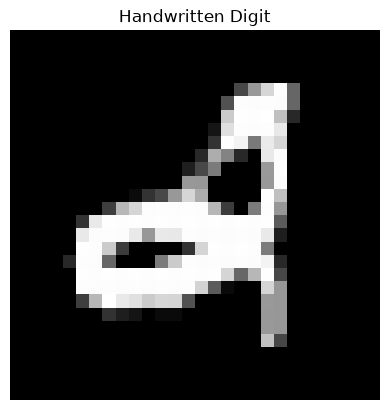

In [19]:
# 简单的查看一个图片
image, y = next(iter(train_set))
print(image.shape, y)
# 显示灰度图像
plt.imshow(image.squeeze(), cmap="gray")

plt.title("Handwritten Digit")
plt.axis("off")
plt.show()

In [20]:
# 2、定义模型
class MNISTCNN(nn.Module):
    def __init__(self, num_classes =  10):
        super(MNISTCNN, self).__init__()
        # 输入图像 [1, 28, 28]，1表示一个通道，是 28 * 28 的图像
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5, padding=2),
            nn.BatchNorm2d(num_features=16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, padding=2),
            nn.BatchNorm2d(num_features=32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, padding=2),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=64 * 3 * 3, out_features=num_classes),
        )
    def forward(self, x):
        x = self.features(x)
        # print(x.shape) # 输出 torch.Size([1, 64, 3, 3]) ，故nn.Linear里面图像的长宽都是3
        return self.classifier(x)

tmc = MNISTCNN()
x = torch.randn(1, 1, 28, 28)
y = tmc(x)
print(y.shape)

torch.Size([1, 10])


In [21]:
# 训练阶段
model = MNISTCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),lr=0.01,momentum=0.9,weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)

best_accuracy = -1.0
best_model_state_dict = None
last_train_loss = None

train_losses, valid_losses = [], []
train_accuracies, valid_accuracies = [], []

# Early Stopping 参数
patience = 5
min_delta = 1e-4
early_stop_counter = 0
best_valid_loss = float("inf")

epochs = 30
for epoch in range(epochs):

    # 训练
    model.train()
    train_sample = 0
    train_loss_sum = 0
    train_correct = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logist = model(images)
        loss = criterion(logist, labels)
        loss.backward()
        optimizer.step()

        # 累计损失
        train_size = images.shape[0]
        train_sample += train_size
        train_loss_sum += loss.item() * train_size

        # 累计正确数
        proba = logist.argmax(dim=1)
        train_correct += proba.eq(labels).sum().item()

    train_loss = train_loss_sum / train_sample
    train_accuracy = train_correct / train_sample
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    last_train_loss = train_loss


    # 验证
    model.eval()
    valid_sample = 0
    valid_loss_sum = 0
    valid_correct = 0
    with torch.inference_mode():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)
            logist = model(images)
            loss = criterion(logist, labels)
            valid_size = images.shape[0]
            valid_sample += valid_size
            valid_loss_sum += loss.item() * valid_size
            proba = logist.argmax(dim=1)
            valid_correct += proba.eq(labels).sum().item()

    valid_loss = valid_loss_sum / valid_sample
    valid_accuracy = valid_correct / valid_sample
    valid_losses.append(valid_loss)
    valid_accuracies.append(valid_accuracy)

    # 保存最佳模型参数
    if valid_accuracy > best_accuracy:
        best_accuracy = valid_accuracy
        best_model_state_dict = copy.deepcopy(model.state_dict())

    # 修改学习率
    scheduler.step()
    current_lr = optimizer.param_groups[0]["lr"]

    # 训练数据输出
    if (epoch + 1) % 10 == 0:
        print(f"epoch: {epoch+1}, current_lr: {current_lr:.4f}, train_loss: {train_loss:.4f}, train_accuracy: {train_accuracy:.4f}, valid_accuracy: {valid_accuracy:.4f}, valid_loss: {valid_loss:.4f}, valid_accuracy: {valid_accuracy:.4f}")

    # Early Stopping
    if current_lr < 1e-4:
        print(f"Epoch {epoch + 1} finished successfully, reason: lr = {current_lr} will be not update")
        break
    # Early Stopping
    if valid_loss < best_valid_loss - min_delta:
        best_valid_loss = valid_loss
        early_stop_counter = 0
    else:
        early_stop_counter += 1

    if early_stop_counter >= patience:
        print(
            f"Early Stopping: "
            f"valid_loss 连续 {patience} 个 Epoch 没有明显改善"
        )
        break

# 保存最佳模型参数
torch.save(best_model_state_dict, "../../data/output/MNISTCNN_best_model_state_dict.pth")
print(f"best_accuracy: {best_accuracy}")


epoch: 10, current_lr: 0.0100, train_loss: 0.0041, train_accuracy: 0.9997, valid_accuracy: 0.9918, valid_loss: 0.0291, valid_accuracy: 0.9918
epoch: 20, current_lr: 0.0010, train_loss: 0.0021, train_accuracy: 1.0000, valid_accuracy: 0.9922, valid_loss: 0.0237, valid_accuracy: 0.9922
epoch: 30, current_lr: 0.0010, train_loss: 0.0014, train_accuracy: 1.0000, valid_accuracy: 0.9935, valid_loss: 0.0223, valid_accuracy: 0.9935
best_accuracy: 0.994


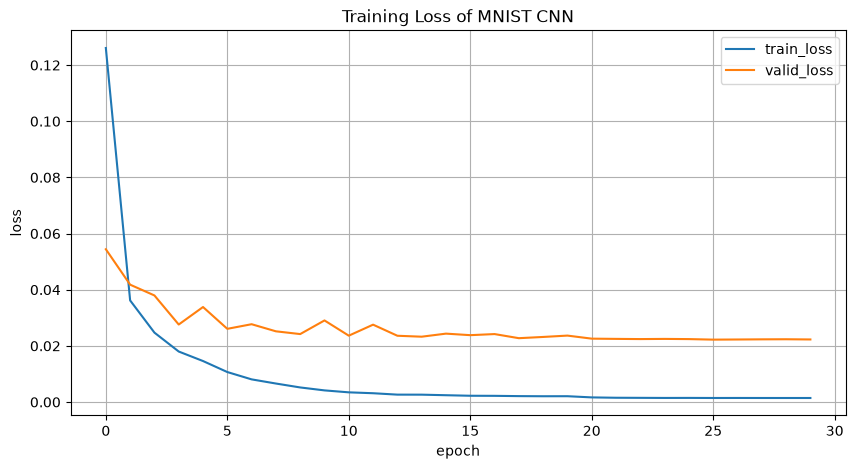

In [22]:
# 训练过程可视化
# loss
plt.figure(figsize=(10,5))
plt.plot(train_losses, label="train_loss")
plt.plot(valid_losses, label="valid_loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training Loss of MNIST CNN")
plt.legend()
plt.grid(True)
plt.show()

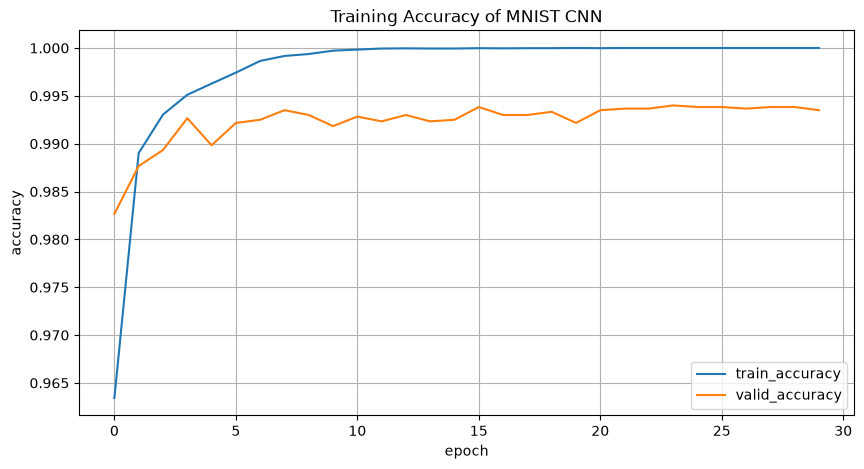

In [23]:
# acc
plt.figure(figsize=(10,5))
plt.plot(train_accuracies, label="train_accuracy")
plt.plot(valid_accuracies, label="valid_accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Training Accuracy of MNIST CNN")
plt.legend()
plt.grid(True)
plt.show()

correct: 9940, total: 10000, Accuracy: 0.9940


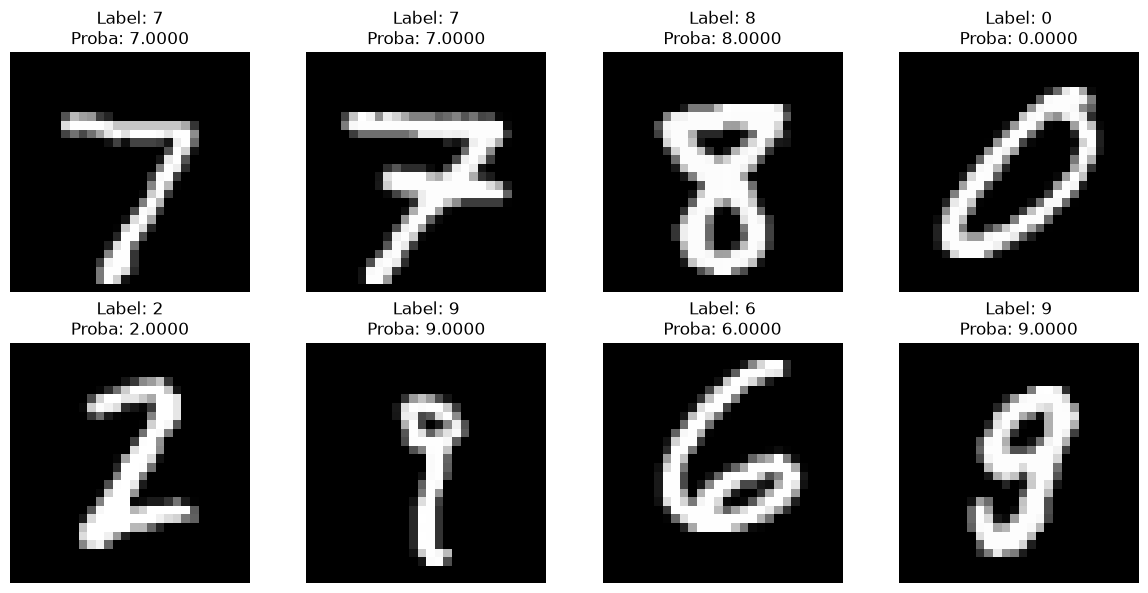

In [24]:
# 测试阶段

# 一般情况下，测试阶段都是要加载训练阶段保存的最佳模型，而不能直接使用训练阶段继承下来的模型，以为训练阶段的模型是最后一次调参的模型，并不是最优的模型
best_model = MNISTCNN().to(device)
best_model_state_dict = torch.load("../../data/output/MNISTCNN_best_model_state_dict.pth", map_location="cpu", weights_only=True)
best_model.load_state_dict(best_model_state_dict)
best_model.eval()

correct, total = 0, 0

# 保存部分图片的数据、真实标签、预测标签
test_pred_data = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logist = best_model(images)
        proba = logist.argmax(dim=1)
        correct += proba.eq(labels).sum().item()
        total += images.shape[0]
        if len(test_pred_data) < 8:
            item = {
                "image": images[0],
                "label": labels[0],
                "proba": proba[0],
            }
            test_pred_data.append(item)

print(f"correct: {correct}, total: {total}, Accuracy: {correct / total:.4f}")

# 测试数据可视化
# 创建 2 行 4 列的画布
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# 将二维 axes 转换为一维，方便遍历
axes = axes.flatten()

for i, item in enumerate(test_pred_data):
    image = item["image"]
    label = item["label"]
    proba = item["proba"]

    # 显示灰度图像
    axes[i].imshow(image.to(torch.device("cpu")).squeeze(), cmap="gray")

    # 显示标题
    axes[i].set_title(
        f"Label: {label}\nProba: {proba:.4f}"
    )

    # 隐藏坐标轴
    axes[i].axis("off")

plt.tight_layout()
plt.show()

